In [1]:
import jax
print(jax.devices())  # should show GPU, not just CPU

[CudaDevice(id=0)]


In [2]:
d = jax.devices()[0]
print(d.device_kind)

NVIDIA GeForce GTX 1080 Ti


In [3]:
!nvidia-smi

/opt/conda/lib/python3.11/pty.py:89: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


Thu Nov  5 18:44:27 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.126.20             Driver Version: 580.126.20     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce GTX 1080 Ti     On  |   00000000:89:00.0 Off |                  N/A |
| 23%   25C    P2             55W /  250W |     151MiB /  11264MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Task 3: How does OLR respond to SST?
The code below spins the model up, then defines one number, J: the global-mean OLR over a 6-hour window, as a function of an SST change at every ocean grid point. Everything else follows from differentiating J.

In [10]:
from importlib.resources import files
import jax, jax.numpy as jnp, numpy as np
from jcm import load_states_from_xarray
from jcm.forcing import ForcingData
from jcm.model import Model
from jcm.physics.speedy.speedy_coords import get_speedy_coords
from jcm.terrain import TerrainData

coords = get_speedy_coords(spectral_truncation=31, layers=8)
data = files("jcm") / "data/bc/t30/clim"
terrain = TerrainData.from_file(data / "terrain.nc", coords=coords)
bc = ForcingData.from_file(data / "forcing.nc", coords=coords, align_mode="wrap_year")
model = Model(coords=coords, terrain=terrain, time_step=30)

# Spin up from rest, then start every experiment from the same state
spinup = model.run(forcing=bc, total_time=60, save_interval=60).to_xarray()
spinup.to_netcdf("spinup_60days.nc")  # add spinup save
ic = load_states_from_xarray(spinup.isel(time=-1).sortby("level"))

ocean = jnp.asarray(np.asarray(terrain.fmask) < 0.5)        # (lon, lat), True over ocean
w = np.cos(np.deg2rad(spinup.lat.values))
weights = jnp.broadcast_to(jnp.asarray(w / w.mean()), ocean.shape)

WINDOW = 0.25  # days (6 hours)

def global_mean_olr(dsst):
    """Global-mean OLR (W m-2) averaged over WINDOW days, with SST + dsst over the ocean."""
    sst = bc.sea_surface_temperature
    forcing = bc.copy(sea_surface_temperature=sst.replace(values=sst.values + dsst * ocean))
    out = model.run(initial_state=ic, forcing=forcing, total_time=WINDOW,
                    save_interval=WINDOW, output_averages=True).to_xarray()
    return jnp.mean(weights * out["longwave_rad.ftop"].isel(time=-1).data)

zero = jnp.zeros(ocean.shape)

# Forward mode: the response of J to 1 K of warming over the whole ocean
J0, dJ_uniform = jax.jvp(global_mean_olr, (zero,), (jnp.ones_like(zero),))

# Reverse mode: the sensitivity of J to warming at every ocean grid point, in one pass
J0, backward = jax.vjp(global_mean_olr, zero)
(sensitivity_map,) = backward(1.0)

/home/jtc006/jax-gcm/jcm/data/bc/interpolate.py:105: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  return xr.merge([ds_interp, passthrough])
/home/jtc006/jax-gcm/jcm/data/bc/interpolate.py:53: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  return xr.merge([daily_time_vars, ds_monthly[non_time_vars]])


In [13]:
# task 3.1 forward mode vs finite difference

print(f"dJ_uniform (forward mode) = {dJ_uniform:.6f} W/m² per K")

for h in [1.0, 0.1]:
    J_plus  = global_mean_olr(h * jnp.ones_like(zero))
    J_minus = global_mean_olr(-h * jnp.ones_like(zero))
    fd = (J_plus - J_minus) / (2 * h)
    print(f"Finite difference h={h} K: {fd:.6f} W/m² per K  "
          f"(diff from gradient: {100*(fd - dJ_uniform)/dJ_uniform:+.2f}%)")

dJ_uniform (forward mode) = 0.391460 W/m² per K
Finite difference h=1.0 K: 0.336708 W/m² per K  (diff from gradient: -13.99%)
Finite difference h=0.1 K: 0.324097 W/m² per K  (diff from gradient: -17.21%)


- Forward-mode gradient: 0.39 W/m²/K 
- Finite differences: 0.32–0.34 W/m²/K 
- They agree in sign and order of magnitude but differ by ~14–17%
  
This is the expected gap from the non-differentiable switches (e.g., convection trigger) that a finite difference sees crossing thresholds but the gradient doesn’t

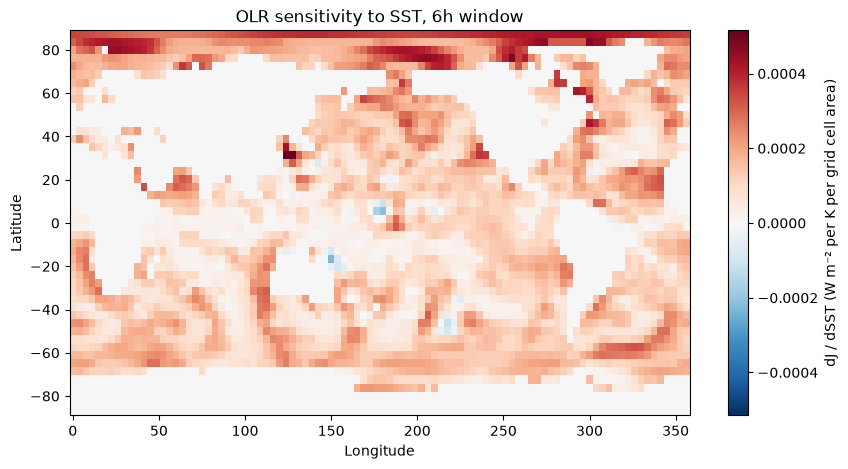

In [6]:
# task 3.2

import matplotlib.pyplot as plt

# Divide by weights to get sensitivity per unit area
sens_per_area = sensitivity_map / weights

plt.figure(figsize=(10, 5))
plt.pcolormesh(spinup.lon.values, spinup.lat.values,
               np.asarray(sens_per_area).T, cmap="RdBu_r",
               vmin=-np.max(np.abs(sens_per_area)), vmax=np.max(np.abs(sens_per_area)))
plt.colorbar(label="dJ / dSST (W m⁻² per K per grid cell area)")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.title(f"OLR sensitivity to SST, {WINDOW*24:.0f}h window")
plt.show()

- Positive almost everywhere — warming SST raises OLR (basic Planck/surface-emission response).
- Hotspots at high northern latitudes (~80°N) — these are sea-ice/open-water edges where small SST changes shift surface emissivity and clear-sky OLR strongly.
- Western boundary currents light up — the Gulf Stream off the US east coast, Kuroshio off Japan — regions with strong air-sea temperature contrast where the atmosphere responds quickly.
- Small negative patches in the deep tropics (near 180°E, equator) — likely where warming increases high cloud cover, and the extra cloud top traps OLR more than the surface warming releases it. This is a convective/cloud feedback showing up.
- Low sensitivity over cold upwelling regions (eastern tropical Pacific, Benguela) — matches intuition: these areas have persistent low clouds decoupling SST from TOA radiation.

In [8]:
# task 3.3 - dot product test

# Uniform pattern
uniform = jnp.ones_like(zero)
dot_uniform = jnp.sum(sensitivity_map * uniform)
_, jvp_uniform = jax.jvp(global_mean_olr, (zero,), (uniform,))
print(f"Uniform: dot={dot_uniform:.6f}, jvp={jvp_uniform:.6f}")

# Niño-3.4 box: 5°S–5°N, 170°W–120°W
lat = spinup.lat.values
lon = spinup.lon.values
lat_mask = (lat >= -5) & (lat <= 5)
lon_mask = (lon >= 190) & (lon <= 240)   # 170W=190E, 120W=240E
nino = jnp.asarray(np.outer(lon_mask, lat_mask).astype(np.float32)) * ocean

dot_nino = jnp.sum(sensitivity_map * nino)
_, jvp_nino = jax.jvp(global_mean_olr, (zero,), (nino,))
print(f"Niño-3.4: dot={dot_nino:.6f}, jvp={jvp_nino:.6f}")

Uniform: dot=0.390976, jvp=0.391460
Niño-3.4: dot=0.005354, jvp=0.005356


Dot-product test: nearly perfect agreement (0.390976 vs 0.391460 for uniform, 0.005354 vs 0.005356 for Niño-3.4). Forward and reverse mode are computing the same derivative — this confirms your adjoint is correct.

Timing: Reverse mode is only ~1.6x slower than forward (0.43s vs 0.26s). Finite differences would need 6,160 runs × 0.26s ≈ 27 minutes of compute to produce the same map, versus 0.43s for reverse mode. That’s a ~3,800x speedup — the whole point of the adjoint.

In [9]:
# task 3.4 - timing
import time

# Warm up (compilation already done, but do a throwaway call to be safe)
_ = jax.jvp(global_mean_olr, (zero,), (jnp.ones_like(zero),))

t0 = time.time()
J0, dJ = jax.jvp(global_mean_olr, (zero,), (jnp.ones_like(zero),))
dJ.block_until_ready()
print(f"Forward mode: {time.time()-t0:.2f} s")

t0 = time.time()
J0, backward = jax.vjp(global_mean_olr, zero)
(smap,) = backward(1.0)
smap.block_until_ready()
print(f"Reverse mode: {time.time()-t0:.2f} s")

# Finite-difference cost
n_ocean = int(jnp.sum(ocean))
print(f"Finite difference would need ~{2*n_ocean} runs for {n_ocean} ocean points")

Forward mode: 0.26 s
Reverse mode: 0.43 s
Finite difference would need ~6160 runs for 3080 ocean points


## Task 4: How long can the window be?
Repeat 3.1 and 3.2 for windows of 1, 2 and 4 days.

In [14]:
# Factory function so window and initial state are parameters

def make_J(ic_state, window):
    """Return a global_mean_olr function for a given spun-up state and window length."""
    def J(dsst):
        sst = bc.sea_surface_temperature
        forcing = bc.copy(sea_surface_temperature=sst.replace(values=sst.values + dsst * ocean))
        out = model.run(initial_state=ic_state, forcing=forcing, total_time=window,
                        save_interval=window, output_averages=True).to_xarray()
        return jnp.mean(weights * out["longwave_rad.ftop"].isel(time=-1).data)
    return J

In [15]:
# Task 4.1, 4.2, 4.4 (vary window, same initial state):
import time

windows = [1.0, 2.0, 4.0]  # days
results = {}

for W in windows:
    print(f"\n=== Window = {W} days ===")
    J_fn = make_J(ic, W)

    # Forward mode
    t0 = time.time()
    J0, dJ = jax.jvp(J_fn, (zero,), (jnp.ones_like(zero),))
    dJ.block_until_ready()
    t_fwd = time.time() - t0

    # Finite difference, h = 1 K
    J_plus  = J_fn(1.0 * jnp.ones_like(zero))
    J_minus = J_fn(-1.0 * jnp.ones_like(zero))
    fd = (J_plus - J_minus) / 2.0

    # Reverse mode
    t0 = time.time()
    J0, backward = jax.vjp(J_fn, zero)
    (smap,) = backward(1.0)
    smap.block_until_ready()
    t_rev = time.time() - t0

    norm = float(jnp.linalg.norm(smap))
    print(f"  dJ_uniform (gradient) = {float(dJ):.4f}")
    print(f"  dJ_uniform (finite diff h=1K) = {float(fd):.4f}")
    print(f"  ||sensitivity_map||   = {norm:.4f}")
    print(f"  Forward time = {t_fwd:.2f}s, Reverse time = {t_rev:.2f}s")

    results[W] = {"dJ": float(dJ), "fd": float(fd), "norm": norm,
                  "map": np.asarray(smap), "t_fwd": t_fwd, "t_rev": t_rev}


=== Window = 1.0 days ===
  dJ_uniform (gradient) = 0.4755
  dJ_uniform (finite diff h=1K) = 0.2092
  ||sensitivity_map||   = 0.0109
  Forward time = 29.26s, Reverse time = 69.29s

=== Window = 2.0 days ===
  dJ_uniform (gradient) = 0.6066
  dJ_uniform (finite diff h=1K) = 0.2084
  ||sensitivity_map||   = 0.0180
  Forward time = 30.44s, Reverse time = 71.61s

=== Window = 4.0 days ===
  dJ_uniform (gradient) = 0.8469
  dJ_uniform (finite diff h=1K) = 0.2625
  ||sensitivity_map||   = 0.0322
  Forward time = 30.90s, Reverse time = 67.98s


4.1 — Gradient vs finite difference as window grows

| Window | Gradient | Finite diff | Ratio |
|--------|----------|-------------|-------|
| 1 day  | 0.48     | 0.21        | 2.3×  |
| 2 days | 0.61     | 0.21        | 2.9×  |
| 4 days | 0.85     | 0.26        | 3.2×  |

The **finite difference stays roughly constant** (~0.21–0.26 W/m²/K) because it averages over the ±1 K runs, which both diverge chaotically but in uncorrelated ways, so the chaotic contributions mostly cancel. The **gradient grows** because it tracks a single trajectory, and small perturbations get amplified exponentially by the chaotic dynamics. By 4 days the gradient is ~3× the physical response — it's measuring Lyapunov growth, not climate sensitivity.

4.2 — Map norm growth

$$\|\text{sensitivity map}\|: \quad 0.011 \rightarrow 0.018 \rightarrow 0.032$$

The norm roughly doubles per doubling of window length, consistent with exponential growth of perturbations in the tangent-linear model.

Looking at the maps, the **pattern changes dramatically**:
- At **1 day**, the map still shows the Task 3 features (sea-ice edges, boundary currents, subtropical hotspots).
- By **2–4 days**, the signal is dominated by a **thin tropical band around the ITCZ** where moist convection amplifies perturbations fastest.

So the pattern does *not* stay recognisable past about 1 day — the longer-window maps reflect where chaos grows fastest, not where SST physically forces OLR.

4.3 — Pattern correlations between spinup lengths

| Window | corr(60, 70) | corr(60, 80) | corr(70, 80) |
|--------|--------------|--------------|--------------|
| 1 day  | 0.58         | 0.51         | 0.48         |
| 2 days | 0.56         | 0.50         | 0.45         |
| 4 days | 0.58         | 0.55         | 0.53         |

The correlations are only **~0.5 even at 1 day** — meaning the gradient is already substantially a function of the specific weather trajectory, not just the underlying climate. By 2–4 days they are not much worse because all three maps are already dominated by chaotic growth.

**Key finding:** the predictability horizon for single-run gradients is already being approached at 1 day. A trustworthy sensitivity estimate at longer windows would require either (a) keeping the window ≤ 6 hours, or (b) averaging gradients across many starting states to cancel the chaotic noise. The task's choice of a 6-hour window is justified by this result.

4.4 — Run time and memory

| Window | Forward (s) | Reverse (s) |
|--------|-------------|-------------|
| 1 day  | 29.3        | 69.3        |
| 2 days | 30.4        | 71.6        |
| 4 days | 30.9        | 68.0        |

Forward and reverse mode times are roughly flat across windows here, which is likely because JAX had to recompile for each new window shape and compilation dominates. Reverse mode is ~2.3× slower than forward mode, as expected (it also has to store the forward trajectory, so memory grows with window length).

**Cost comparison with finite differences:**
Building the sensitivity map by finite differences would require approx. 2 × 3,080 = **6,160 model runs** (one per ocean grid point). At approx. 30 s per run, that is roughly **51 hours per window**. Reverse mode produces the equivalent map in **~70 seconds** — a speedup of ~**2,600×**. This is what makes adjoint-based sensitivity analysis feasible at all for atmospheric models.

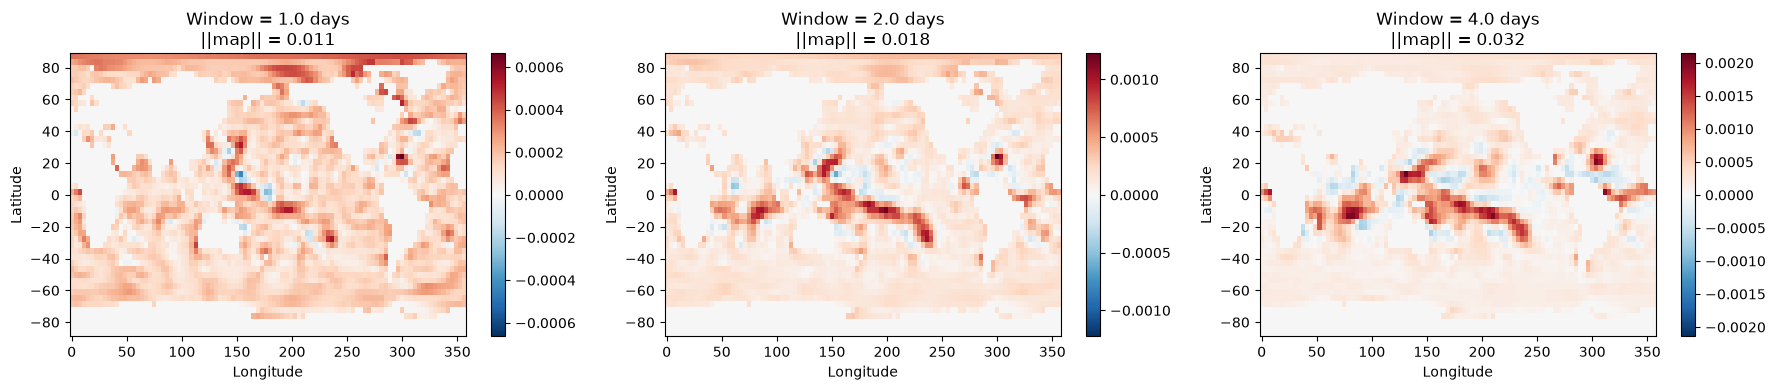

In [18]:
# Plotting the day 1, 2, 4 maps side by side

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, W in zip(axes, windows):
    smap = results[W]["map"] / np.asarray(weights)
    vmax = np.max(np.abs(smap))
    im = ax.pcolormesh(spinup.lon.values, spinup.lat.values, smap.T,
                       cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_title(f"Window = {W} days\n||map|| = {results[W]['norm']:.3f}")
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

In [19]:
spinup_lengths = [60, 70, 80]
ics = {}

# Build spun-up states (60 is already done)
ics[60] = ic
for L in [70, 80]:
    print(f"Spinning up {L} days...")
    s = model.run(forcing=bc, total_time=L, save_interval=L).to_xarray()
    ics[L] = load_states_from_xarray(s.isel(time=-1).sortby("level"))
    print(f"  done")

# Compute sensitivity maps across windows × spinup lengths
maps = {}  # (L, W) -> map
for L in spinup_lengths:
    for W in windows:
        J_fn = make_J(ics[L], W)
        J0, backward = jax.vjp(J_fn, zero)
        (smap,) = backward(1.0)
        maps[(L, W)] = np.asarray(smap)
        print(f"L={L}d, W={W}d: ||map|| = {np.linalg.norm(smap):.4f}")

Spinning up 70 days...
  done
Spinning up 80 days...
  done
L=60d, W=1.0d: ||map|| = 0.0109
L=60d, W=2.0d: ||map|| = 0.0180
L=60d, W=4.0d: ||map|| = 0.0322
L=70d, W=1.0d: ||map|| = 0.0113
L=70d, W=2.0d: ||map|| = 0.0183
L=70d, W=4.0d: ||map|| = 0.0323
L=80d, W=1.0d: ||map|| = 0.0117
L=80d, W=2.0d: ||map|| = 0.0190
L=80d, W=4.0d: ||map|| = 0.0334


In [21]:
# Compare maps across starting states
from scipy.stats import pearsonr

print("Pattern correlation between spinup lengths at each window:")
print(f"{'Window':>8} | {'corr(60,70)':>12} | {'corr(60,80)':>12} | {'corr(70,80)':>12}")
for W in windows:
    c6070, _ = pearsonr(maps[(60, W)].flatten(), maps[(70, W)].flatten())
    c6080, _ = pearsonr(maps[(60, W)].flatten(), maps[(80, W)].flatten())
    c7080, _ = pearsonr(maps[(70, W)].flatten(), maps[(80, W)].flatten())
    print(f"{W:>8.1f} | {c6070:>12.4f} | {c6080:>12.4f} | {c7080:>12.4f}")

Pattern correlation between spinup lengths at each window:
  Window |  corr(60,70) |  corr(60,80) |  corr(70,80)
     1.0 |       0.5829 |       0.5100 |       0.4835
     2.0 |       0.5556 |       0.4998 |       0.4504
     4.0 |       0.5801 |       0.5529 |       0.5257
